# Assignment 3: predicting blood-brain barrier penetration from molecular graphs

Mohamed Abdalla (25011148), ENG 2440.

This is a coursework experiment on a benchmark dataset. Nothing in it says whether a real compound
crosses the barrier in a person.

**What the sections do.** A loads and cleans the data, B turns molecules into graphs and checks the
batching, C builds the random and the scaffold split, D trains the fingerprint baseline, E trains
the GNN, F compares them, G looks at what the GNN got wrong, and H says what this cannot support.

**How the code is laid out.** Every section starts with a comment block saying what it takes and
what it returns, then its functions, then the cells that run them. Each function carries a two-line
docstring: what it is, then its input and output. The intent is that any single function can be read
and explained on its own, without reading the rest of the notebook.

**How to run it.** Top to bottom on a fresh kernel. Cell 2 holds every tunable value, and the two
seeds there (42 for the splits and the baseline, 1/2/3 for the GNN) are the only randomness. It
takes about 2.5 minutes on a laptop CPU. It writes its figures to `report/figures/` and its tables
to `results/`, creating both folders if they are missing. The dataset downloads itself into `data/`
on the first run.

In [1]:
# first run only; PyTorch must already be installed
# !pip -q install torch-geometric rdkit scikit-learn matplotlib pandas

In [2]:
import copy
import random
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from torch import nn
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_mean_pool
from torch_geometric.utils.smiles import e_map, x_map

RDLogger.DisableLog("rdApp.*")
Path("report/figures").mkdir(parents=True, exist_ok=True)
Path("results").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/Users/mohamed.abdalla/Documents/Fall26/Medical Imaging & AI in Healthcare/Assignments/A3/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
# every tunable value lives here
SEED = 42                       # seed for both data splits and the baseline
MODEL_SEEDS = [1, 2, 3]         # GNN initialisation / batch-order seeds
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)
DATA_ROOT = "data/MoleculeNet"

FP_RADIUS = 2
FP_BITS = 2048
LOGREG_C_GRID = [0.01, 0.1, 1.0, 10.0]
LOGREG_CLASS_WEIGHTS = [None, "balanced"]

GNN_CONFIG = {"hidden_dim": 64, "num_layers": 3, "dropout": 0.2, "learning_rate": 1e-3,
              "weight_decay": 1e-5, "batch_size": 64, "max_epochs": 80, "patience": 15}
print("split/baseline seed:", SEED, "| GNN seeds:", MODEL_SEEDS)

split/baseline seed: 42 | GNN seeds: [1, 2, 3]


## A. What the task is, and what is actually in the data

The model gets one molecule as a SMILES string, I turn it into a graph where atoms are nodes and
bonds are edges, and it returns one probability that the molecule crosses the blood-brain barrier.
One molecule is one sample, so the prediction has to come from the whole graph, not from each atom.
I am using this only to compare a fingerprint model against a GNN under two different splits.

Label 1 means the source recorded the compound as penetrating, 0 as not penetrating. These came out
of the literature, so they are someone's reading of an experiment, not something I can verify.

Below I check the size of the dataset, the labels, the class balance, and duplicates. The duplicate
check is the one that matters: the same molecule can be written as two different SMILES strings, so
I canonicalize everything with RDKit first, otherwise the duplicates stay invisible and can end up
on both sides of a split.

In [4]:
# Section A: read the BBBP file and clean it down to one row per molecule.
# Takes: DATA_ROOT, the folder MoleculeNet downloads BBBP.csv into.
# Returns:
# - count_raw_problems: what the raw csv has that never reaches the loader.
# - build_record_table: one row per loaded graph, with canonical SMILES, label and size.
# - clean_table: the cleaned table, plus a count of what every cleaning step removed.
# Cleaning happens before either split is built, so no duplicate can cross a split.


def canonicalize(smiles: str) -> str | None:
    """RDKit's one agreed spelling for a molecule, so duplicates stop hiding.
    Input: one SMILES string. Output: its canonical SMILES, or None if unreadable."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol)


def count_raw_problems(root: str) -> dict:
    """Problems in the raw csv, counted before trusting what the loader returns.
    Input: the dataset root folder. Output: raw rows, missing labels, unreadable SMILES."""
    # the PyG loader silently drops rows RDKit cannot parse, so count them in the raw CSV
    raw = pd.read_csv(Path(root) / "BBBP" / "raw" / "BBBP.csv")
    unparsable = [Chem.MolFromSmiles(s) is None for s in raw["smiles"]]
    return {
        "raw_rows": len(raw),
        "raw_missing_labels": int(raw["p_np"].isna().sum()),
        "raw_unparsable_smiles": int(sum(unparsable)),
    }


def build_record_table(dataset) -> pd.DataFrame:
    """One row per loaded graph, with its canonical SMILES, label and size.
    Input: the loaded dataset. Output: a table with one row per molecule."""
    rows = []
    for position, graph in enumerate(dataset):
        label = float(graph.y.item())
        rows.append(
            {
                "dataset_idx": position,
                "smiles": graph.smiles,
                "canonical": canonicalize(graph.smiles),
                "label": label,
                "n_atoms": graph.num_nodes,
                "n_bonds": graph.edge_index.shape[1] // 2,
            }
        )
    return pd.DataFrame(rows)


def find_bad_records(table: pd.DataFrame) -> pd.Series:
    """Marks rows with an unreadable SMILES, a non-finite label, or no atoms.
    Input: the record table. Output: true or false for each row."""
    has_bad_smiles = table["canonical"].isna()
    has_bad_label = ~np.isfinite(table["label"])
    is_empty = table["n_atoms"] == 0
    return has_bad_smiles | has_bad_label | is_empty


def summarize_duplicates(table: pd.DataFrame) -> dict:
    """Molecules that appear twice, and whether their copies agree on the label.
    Input: the record table. Output: the duplicate counts and the conflicting molecules."""
    groups = table.groupby("canonical")
    group_sizes = groups.size()
    repeated = group_sizes[group_sizes > 1].index
    repeated_rows = table[table["canonical"].isin(repeated)]
    n_labels = repeated_rows.groupby("canonical")["label"].nunique()
    n_spellings = repeated_rows.groupby("canonical")["smiles"].nunique()
    return {
        "repeated_molecules": len(repeated),
        "records_in_repeated_groups": len(repeated_rows),
        "groups_with_different_spellings": int((n_spellings > 1).sum()),
        "groups_with_conflicting_labels": int((n_labels > 1).sum()),
        "conflicting_canonical": list(n_labels[n_labels > 1].index),
    }


def clean_table(table: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Drops bad rows, drops label conflicts, then keeps one copy of each molecule.
    Input: the record table. Output: the cleaned table and what each step removed."""
    bad = find_bad_records(table)
    valid = table[~bad]
    duplicates = summarize_duplicates(valid)
    in_conflict = valid["canonical"].isin(duplicates["conflicting_canonical"])
    consistent = valid[~in_conflict]
    kept = consistent.drop_duplicates(subset="canonical", keep="first")
    counts = {
        "bad_records_removed": int(bad.sum()),
        "conflicting_records_removed": int(in_conflict.sum()),
        "consistent_duplicates_removed": len(consistent) - len(kept),
        "records_after_cleaning": len(kept),
    }
    return kept.reset_index(drop=True), {**duplicates, **counts}

In [5]:
# Load BBBP once, and count the raw rows before the loader gets to decide anything.
dataset = MoleculeNet(root=DATA_ROOT, name="BBBP")
raw_problems = count_raw_problems(DATA_ROOT)
table = build_record_table(dataset)
print(dataset, "| raw CSV:", raw_problems)
print("graphs loaded by PyG:", len(table))

BBBP(2039) | raw CSV: {'raw_rows': 2050, 'raw_missing_labels': 0, 'raw_unparsable_smiles': 11}
graphs loaded by PyG: 2039


In [6]:
# The three things that could be wrong with a label, and how the classes are balanced.
labels = table["label"]
counts = labels.value_counts().sort_index()
print("non-finite labels:", int((~np.isfinite(labels)).sum()))
print("invalid canonical SMILES among loaded graphs:", int(table["canonical"].isna().sum()))
print("empty graphs (0 atoms):", int((table["n_atoms"] == 0).sum()))
print("class counts:", counts.to_dict())
print("class proportions:", (counts / len(table)).round(4).to_dict())

non-finite labels: 0
invalid canonical SMILES among loaded graphs: 0
empty graphs (0 atoms): 0
class counts: {0.0: 479, 1.0: 1560}
class proportions: {0.0: 0.2349, 1.0: 0.7651}


In [7]:
# Clean the table, and show the 10 duplicate groups whose labels disagree.
clean, cleaning = clean_table(table)
conflicts = table[table["canonical"].isin(cleaning["conflicting_canonical"])]
print({k: v for k, v in cleaning.items() if k != "conflicting_canonical"})
display(conflicts.sort_values("canonical")[["canonical", "smiles", "label"]].head(12))
print("labels after cleaning:", clean["label"].value_counts().sort_index().to_dict())
clean.to_csv("results/clean_table.csv", index=False)

{'repeated_molecules': 60, 'records_in_repeated_groups': 124, 'groups_with_different_spellings': 60, 'groups_with_conflicting_labels': 10, 'bad_records_removed': 0, 'conflicting_records_removed': 20, 'consistent_duplicates_removed': 54, 'records_after_cleaning': 1965}


,canonical,smiles,label
98,CC(=O)Oc1ccccc1C(=O)O,CC(=O)Oc1ccccc1C(O)=O,0.0
996,CC(=O)Oc1ccccc1C(=O)O,C1=CC=CC(=C1C(O)=O)OC(C)=O,1.0
1323,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1,C1=CC(=CC2=C1C(C3=C(CC2)C=CC=N3)=C4CCN(C(OCC)=...,1.0
566,CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1,CCOC(=O)N1CCC(CC1)=C2c3ccc(Cl)cc3CCc4cccnc24,0.0
16,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccc...,CN(C)C(=O)C(CCN1CCC(O)(CC1)c1ccc(Cl)cc1)(c1ccc...,1.0
547,CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccc...,CN(C)C(=O)C(CCN1CCC(O)(CC1)c2ccc(Cl)cc2)(c3ccc...,0.0
124,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,CN1C2CCC1CC(C2)OC(=O)C(CO)c3ccccc3,0.0
1686,CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2,C1=CC=CC=C1C(C(OC2CC3N(C)C(C2)CC3)=O)CO,1.0
172,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,0.0
1630,COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC,C1=C3C(=C(C(=C1)CNC2=CC(=C(C(=C2)OC)OC)OC)C)C(...,1.0


labels after cleaning: {0.0: 465, 1.0: 1500}


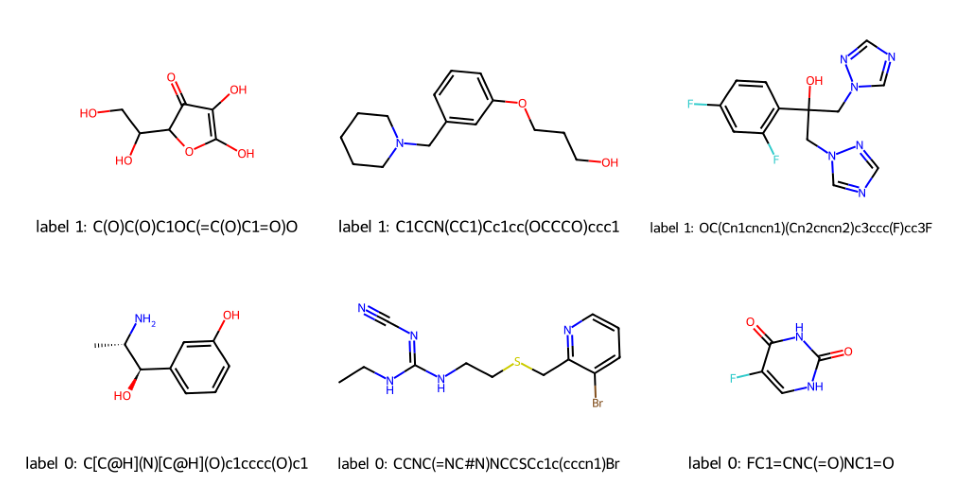

In [8]:
# 3 positive and 3 negative molecules, each with SMILES and label in the legend
short = clean[clean["smiles"].str.len() <= 34]   # whole SMILES fits under the drawing
shown = pd.concat([short[short["label"] == 1].sample(3, random_state=SEED),
                   short[short["label"] == 0].sample(3, random_state=SEED)])
mols = [Chem.MolFromSmiles(s) for s in shown["smiles"]]
legends = [f"label {int(l)}: {s}" for s, l in zip(shown["smiles"], shown["label"])]
draw_options = Draw.MolDrawOptions(); draw_options.legendFontSize = 17
grid = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(330, 250), legends=legends,
                            drawOptions=draw_options, returnPNG=False)
plt.figure(figsize=(9, 4.6)); plt.imshow(grid); plt.axis("off"); plt.tight_layout()
plt.savefig("report/figures/fig_examples.png", dpi=170, bbox_inches="tight"); plt.show()

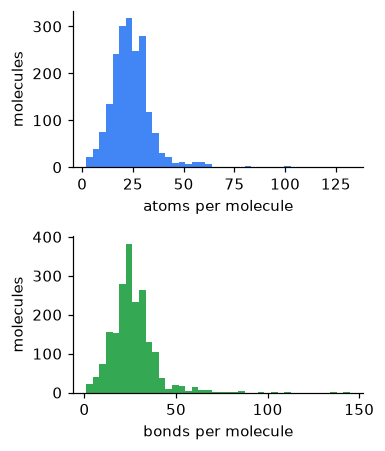

       n_atoms  n_bonds
count   1965.0   1965.0
mean      24.2     26.1
std       10.7     11.8
min        2.0      1.0
25%       18.0     19.0
50%       23.0     25.0
75%       29.0     31.0
max      132.0    145.0
x.shape: (20, 9) | edge_index.shape: (2, 40) | edge_attr.shape: (40, 3)
y: tensor([[1.]]) | smiles: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [9]:
# How big the molecules are, and what one PyG graph actually holds.
fig, axes = plt.subplots(2, 1, figsize=(3.6, 4.2))
axes[0].hist(clean["n_atoms"], bins=40, color="#4285F4"); axes[0].set_xlabel("atoms per molecule")
axes[1].hist(clean["n_bonds"], bins=40, color="#34A853"); axes[1].set_xlabel("bonds per molecule")
axes[0].set_ylabel("molecules"); axes[1].set_ylabel("molecules"); plt.tight_layout()
plt.savefig("report/figures/fig_size_dist.png", dpi=170); plt.show()
print(clean[["n_atoms", "n_bonds"]].describe().round(1))

graph = dataset[0]
print("x.shape:", tuple(graph.x.shape), "| edge_index.shape:", tuple(graph.edge_index.shape),
      "| edge_attr.shape:", tuple(graph.edge_attr.shape))
print("y:", graph.y, "| smiles:", graph.smiles)

## B. Turning molecules into graphs, and batching them

Each PyG graph has `x` (one row per atom, 9 categorical columns), `edge_index` (atom pairs, each bond
listed once in each direction so messages can travel both ways), `edge_attr` (one row per directed
bond, 3 categorical columns), `y` and `smiles`.

The columns are category codes, not numbers. Carbon is 6 and nitrogen is 7, but nitrogen is not
"one more than" carbon, and that is exactly what a linear layer would assume if I fed the integers
in directly. So each column goes through its own `nn.Embedding` table and I add the vectors together.
That is the same thing as one-hot encoding each column and multiplying by a weight matrix, but it
keeps the width at 64 instead of the 177 columns a full one-hot would need.

In [10]:
# What each of the 9 atom columns and 3 bond columns mean, and how many categories each has.
atom_meaning = ["element (atomic number)", "chirality tag", "number of bonded neighbours", "formal charge",
                "attached hydrogens", "unpaired (radical) electrons", "hybridization (sp, sp2, ...)",
                "aromatic atom (0/1)", "atom is in a ring (0/1)"]
bond_meaning = ["bond type (single, double, triple, aromatic, ...)", "stereo tag (E/Z)", "conjugated bond (0/1)"]
atom_columns = pd.DataFrame({"column": list(x_map.keys()), "categories": [len(v) for v in x_map.values()], "meaning": atom_meaning})
bond_columns = pd.DataFrame({"column": list(e_map.keys()), "categories": [len(v) for v in e_map.values()], "meaning": bond_meaning})
print("atom feature columns (graph.x, column 0 to 8):"); display(atom_columns)
print("bond feature columns (graph.edge_attr, column 0 to 2):"); display(bond_columns)

atom feature columns (graph.x, column 0 to 8):


,column,categories,meaning
0,atomic_num,119,element (atomic number)
1,chirality,9,chirality tag
2,degree,11,number of bonded neighbours
3,formal_charge,12,formal charge
4,num_hs,9,attached hydrogens
5,num_radical_electrons,5,unpaired (radical) electrons
6,hybridization,8,"hybridization (sp, sp2, ...)"
7,is_aromatic,2,aromatic atom (0/1)
8,is_in_ring,2,atom is in a ring (0/1)


bond feature columns (graph.edge_attr, column 0 to 2):


,column,categories,meaning
0,bond_type,22,"bond type (single, double, triple, aromatic, ...)"
1,stereo,6,stereo tag (E/Z)
2,is_conjugated,2,conjugated bond (0/1)


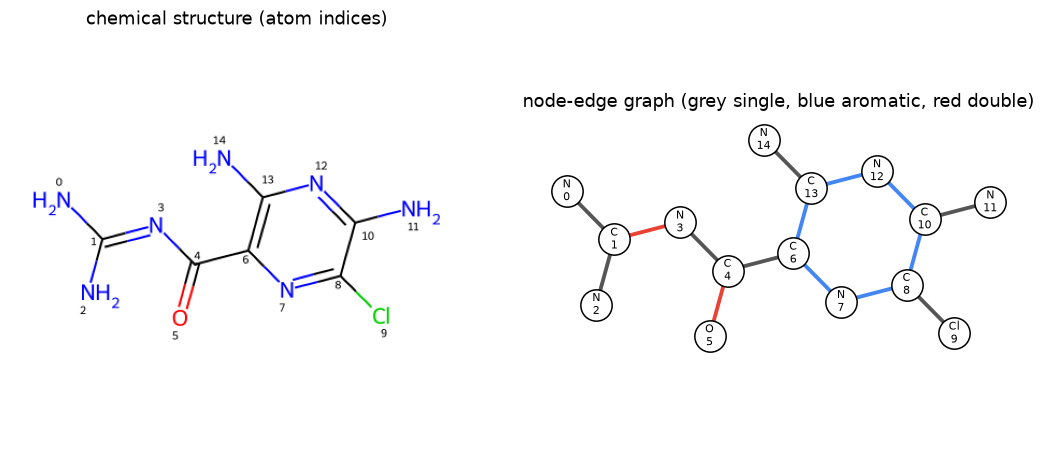

NC(N)=NC(=O)c1nc(Cl)c(N)nc1N | atoms: 15 | undirected bonds: 15


In [11]:
# pick a small ring molecule so the two views are easy to compare
candidates = clean[(clean["n_atoms"].between(11, 15)) & (clean["canonical"].str.contains("1"))]
example_row = candidates.iloc[0]
example = dataset[int(example_row["dataset_idx"])]
mol = Chem.MolFromSmiles(example.smiles)
Chem.rdDepictor.Compute2DCoords(mol)
symbols = [Chem.GetPeriodicTable().GetElementSymbol(int(z)) for z in example.x[:, 0]]
bond_names = e_map["bond_type"]
colours = {"SINGLE": "#555555", "DOUBLE": "#EA4335", "AROMATIC": "#4285F4", "TRIPLE": "#FBBC04"}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
options = Draw.MolDrawOptions(); options.addAtomIndices = True
axes[0].imshow(Draw.MolToImage(mol, size=(420, 380), options=options)); axes[0].axis("off")
axes[0].set_title("chemical structure (atom indices)")
positions = {i: mol.GetConformer().GetAtomPosition(i) for i in range(mol.GetNumAtoms())}
for src, dst in example.edge_index[:, example.edge_index[0] < example.edge_index[1]].T.tolist():
    bond_id = int(example.edge_attr[(example.edge_index[0] == src) & (example.edge_index[1] == dst)][0, 0])
    colour = colours.get(str(bond_names[bond_id]), "#999999")
    axes[1].plot([positions[src].x, positions[dst].x], [positions[src].y, positions[dst].y], color=colour, lw=2.5, zorder=1)
for i, symbol in enumerate(symbols):
    axes[1].scatter(positions[i].x, positions[i].y, s=420, color="white", edgecolor="black", zorder=2)
    axes[1].text(positions[i].x, positions[i].y, f"{symbol}\n{i}", ha="center", va="center", fontsize=7, zorder=3)
axes[1].set_title("node-edge graph (grey single, blue aromatic, red double)"); axes[1].axis("off")
axes[1].set_aspect("equal"); axes[1].margins(0.12); plt.tight_layout()
plt.savefig("report/figures/fig_graph_views.png", dpi=170); plt.show()
print(example.smiles, "| atoms:", example.num_nodes, "| undirected bonds:", example.edge_index.shape[1] // 2)

In [12]:
# Section B checks: nothing empty reaches training, and batching loses no molecule.

clean_dataset = dataset[clean["dataset_idx"].tolist()]   # position i matches row i of `clean`

def check_graphs(graphs) -> None:
    """Every graph has at least one atom and a label the loss can use.
    Input: the graphs. Output: nothing, it raises if one is unusable."""
    for graph in graphs:
        assert graph.num_nodes >= 1, "empty graph kept"
        assert torch.isfinite(graph.y).all(), "non-finite label"

def check_batching(loader, expected_smiles: list, expected_atoms: int) -> None:
    """One pass over the loader returns every molecule and every atom exactly once.
    Input: the loader, the expected SMILES and atom count. Output: nothing, it raises."""
    seen_smiles, seen_atoms = [], 0
    for batch in loader:
        assert batch.y.view(-1).shape[0] == batch.num_graphs, "labels do not match graph count"
        assert int(batch.batch.max()) + 1 == batch.num_graphs, "batch vector disagrees with graph count"
        seen_smiles += list(batch.smiles)
        seen_atoms += batch.x.shape[0]
    assert sorted(seen_smiles) == sorted(expected_smiles), "a molecule was lost or duplicated"
    assert seen_atoms == expected_atoms, "atoms were lost in batching"

check_graphs(clean_dataset)
loader = DataLoader(clean_dataset, batch_size=GNN_CONFIG["batch_size"], shuffle=False)
check_batching(loader, clean["smiles"].tolist(), int(clean["n_atoms"].sum()))
batch = next(iter(loader))
print("x:", tuple(batch.x.shape), "| edge_index:", tuple(batch.edge_index.shape),
      "| edge_attr:", tuple(batch.edge_attr.shape), "| batch:", tuple(batch.batch.shape), "| y:", tuple(batch.y.shape))
print("graphs in batch:", batch.num_graphs, "| all checks passed on", len(clean_dataset), "graphs")

x: (1522, 9) | edge_index: (2, 3276) | edge_attr: (3276, 3) | batch: (1522,) | y: (64, 1)
graphs in batch: 64 | all checks passed on 1965 graphs


A batch of 64 molecules becomes one big graph with no edges between the molecules. That is how PyG
avoids padding graphs to a common size.

`x` stacks every atom in the batch, so its first dimension is a sum over the 64 molecules rather
than a fixed number. `edge_index` gets renumbered as the molecules are stacked, so the second
molecule's atom 0 becomes atom 23 or wherever the first one ended. Without that, the molecules would
share atoms. `batch` records which molecule each atom came from, and that is what lets pooling turn
1,522 atom vectors back into 64 molecule vectors. `y` has one label per molecule, not per atom.

Since the renumbering happens silently, I check it instead of trusting it. The last assert is the
real one: if a molecule were dropped or counted twice, everything downstream would still compute
fine, just on the wrong set.

Left is the ordinary drawing, right is the same molecule as a graph. The circles are atoms with the
same index and element as on the left, and the lines are bonds coloured by type.

The only thing the graph throws away is where RDKit decided to put the atoms on the page, which is a
drawing convention and not chemistry. That is the whole point: two different drawings of the same
molecule give the same graph.

## C. Two splits: random and scaffold (70/15/15, seed 42)

A Bemis-Murcko scaffold is what is left of a molecule once the side chains are stripped off, so
molecules sharing one are variations on the same skeleton. Keeping a whole scaffold group inside a
single subset is what stops those variations from sitting on both sides of the split.

Two things needed deciding. Molecules with no rings have an empty scaffold, and RDKit returns an
empty string for all of them, which would silently pool 95 unrelated molecules into one group. I
kept that behaviour on purpose and called the group `acyclic`, so they all land together. The
alternative, giving each its own group, would let a molecule and its near-twin end up on opposite
sides, which is the exact thing this split is supposed to prevent. Second, any scaffold group bigger
than half a validation set goes to train first, so one large family cannot swallow the validation or
test set. The rest get shuffled with the seed and dealt into train, val and test in that order.

In [13]:
# Section C: build the two splits, then prove each one is sound.
# Takes: the cleaned labels, and one Bemis-Murcko scaffold per molecule.
# Returns:
# - make_random_split and make_scaffold_split: train, validation and test positions.
# - check_split and check_scaffolds_disjoint: nothing, they raise if a subset leaks.
# - describe_split: the size, positive share and scaffold count of each subset.

ACYCLIC = "acyclic"


def get_scaffold(smiles: str) -> str:
    """The ring skeleton left after the side chains are stripped, so analogues group together.
    Input: one SMILES string. Output: its scaffold SMILES, or "acyclic" if it has no rings."""
    mol = Chem.MolFromSmiles(smiles)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    # molecules without rings have an empty scaffold; give them one shared group
    return scaffold if scaffold else ACYCLIC


def make_random_split(labels: np.ndarray, seed: int, fractions: tuple) -> dict:
    """Splits the molecules 70/15/15, keeping the class balance inside each subset.
    Input: the labels, a seed and the three fractions. Output: the positions per subset."""
    train_frac, val_frac, test_frac = fractions
    positions = np.arange(len(labels))
    train, rest = train_test_split(
        positions, test_size=val_frac + test_frac, stratify=labels, random_state=seed
    )
    test_share = test_frac / (val_frac + test_frac)
    val, test = train_test_split(
        rest, test_size=test_share, stratify=labels[rest], random_state=seed
    )
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


def make_scaffold_split(scaffolds: list, seed: int, fractions: tuple) -> dict:
    """Splits the molecules 70/15/15, keeping a whole scaffold group inside one subset.
    Input: the scaffolds, a seed and the three fractions. Output: the positions per subset."""
    n_total = len(scaffolds)
    train_size = fractions[0] * n_total
    val_size = fractions[1] * n_total
    groups = defaultdict(list)
    for position, scaffold in enumerate(scaffolds):
        groups[scaffold].append(position)
    # groups over half a validation set go to train first, so val/test get small scaffolds
    big = [g for g in groups.values() if len(g) > val_size / 2]
    small = [g for g in groups.values() if len(g) <= val_size / 2]
    random.Random(seed).shuffle(small)
    chosen = {"train": [], "val": [], "test": []}
    for group in big + small:
        if len(chosen["train"]) + len(group) <= train_size:
            chosen["train"] += group
        elif len(chosen["val"]) + len(group) <= val_size:
            chosen["val"] += group
        else:
            chosen["test"] += group
    return {name: np.sort(np.array(idx)) for name, idx in chosen.items()}


def check_split(split: dict, table: pd.DataFrame) -> None:
    """Every molecule is used once, and no molecule sits in two subsets.
    Input: a split and the cleaned table. Output: nothing, it raises on a leak."""
    train, val, test = split["train"], split["val"], split["test"]
    all_positions = np.concatenate([train, val, test])
    assert len(all_positions) == len(table), "split does not cover every molecule"
    assert len(set(all_positions)) == len(table), "an index appears in two subsets"
    canon = {name: set(table["canonical"].iloc[idx]) for name, idx in split.items()}
    assert not canon["train"] & canon["val"], "train/val share a canonical SMILES"
    assert not canon["train"] & canon["test"], "train/test share a canonical SMILES"
    assert not canon["val"] & canon["test"], "val/test share a canonical SMILES"


def check_scaffolds_disjoint(split: dict, scaffolds: list) -> None:
    """No scaffold group is shared between train, validation and test.
    Input: a split and the scaffolds. Output: nothing, it raises on a shared scaffold."""
    sets = {name: {scaffolds[i] for i in idx} for name, idx in split.items()}
    assert not sets["train"] & sets["val"], "train/val share a scaffold"
    assert not sets["train"] & sets["test"], "train/test share a scaffold"
    assert not sets["val"] & sets["test"], "val/test share a scaffold"


def describe_split(split: dict, table: pd.DataFrame, scaffolds: list) -> pd.DataFrame:
    """The size, positive share and scaffold count of each subset.
    Input: a split, the cleaned table and the scaffolds. Output: one row per subset."""
    rows = []
    for name, idx in split.items():
        rows.append(
            {
                "subset": name,
                "molecules": len(idx),
                "positive_fraction": table["label"].iloc[idx].mean(),
                "unique_scaffolds": len({scaffolds[i] for i in idx}),
            }
        )
    return pd.DataFrame(rows)

In [14]:
# Build both splits from the cleaned table, then check them before using either one.
y = clean["label"].to_numpy().astype(int)
scaffolds = [get_scaffold(s) for s in clean["smiles"]]
splits = {"random": make_random_split(y, SEED, SPLIT_FRACTIONS),
          "scaffold": make_scaffold_split(scaffolds, SEED, SPLIT_FRACTIONS)}

for name, split in splits.items():
    check_split(split, clean)
check_scaffolds_disjoint(splits["scaffold"], scaffolds)
print("coverage, disjoint indices, no shared canonical SMILES: passed for both splits")
print("scaffold sets disjoint across train/val/test: passed")
print("acyclic molecules in cleaned data:", scaffolds.count(ACYCLIC), "| unique scaffolds overall:", len(set(scaffolds)))

summary = pd.concat({name: describe_split(sp, clean, scaffolds) for name, sp in splits.items()})
summary["positive_fraction"] = summary["positive_fraction"].round(3)
summary.to_csv("results/split_summary.csv"); display(summary)

coverage, disjoint indices, no shared canonical SMILES: passed for both splits
scaffold sets disjoint across train/val/test: passed
acyclic molecules in cleaned data: 95 | unique scaffolds overall: 1020


subset  molecules  positive_fraction  unique_scaffolds
random   0  train       1375              0.764               773
         1    val        295              0.763               225
         2   test        295              0.763               226
scaffold 0  train       1375              0.764               649
         1    val        294              0.762               182
         2   test        296              0.764               189

random: mean nearest-train Tanimoto = 0.556, test molecules with similarity >= 0.7: 28.5%
scaffold: mean nearest-train Tanimoto = 0.451, test molecules with similarity >= 0.7: 6.1%
random: test molecules whose scaffold also appears in train: 53.2%
scaffold: test molecules whose scaffold also appears in train: 0.0%


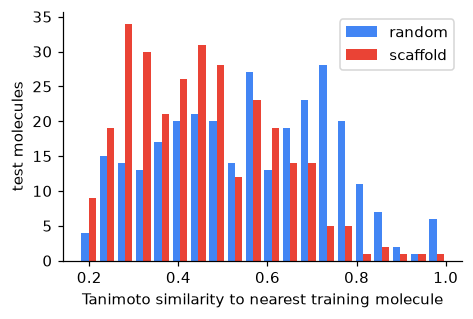

In [15]:
# Section C check: how far each test molecule sits from the training set it never saw.
# A random split can leave a near-copy in train; a scaffold split should not.


def make_bit_vectors(smiles_list: list, radius: int, n_bits: int) -> list:
    """Morgan fingerprints: which circular substructures each molecule contains.
    Input: SMILES strings, the radius and the bit count. Output: one bit vector each."""
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    return [generator.GetFingerprint(Chem.MolFromSmiles(s)) for s in smiles_list]


def nearest_train_similarity(split: dict) -> np.ndarray:
    """How close each test molecule is to the nearest molecule the model trained on.
    Input: a split. Output: one Tanimoto similarity per test molecule."""
    train_vectors = [bit_vectors[i] for i in split["train"]]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(bit_vectors[i], train_vectors))
                     for i in split["test"]])


bit_vectors = make_bit_vectors(clean["canonical"].tolist(), FP_RADIUS, FP_BITS)
nearest = {name: nearest_train_similarity(sp) for name, sp in splits.items()}
for name, values in nearest.items():
    print(f"{name}: mean nearest-train Tanimoto = {values.mean():.3f}, test molecules with similarity >= 0.7: {(values >= 0.7).mean():.1%}")
for name, split in splits.items():
    train_scaffolds = {scaffolds[i] for i in split["train"]}
    shared = np.mean([scaffolds[i] in train_scaffolds for i in split["test"]])
    print(f"{name}: test molecules whose scaffold also appears in train: {shared:.1%}")
plt.figure(figsize=(4.4, 3))
plt.hist([nearest["random"], nearest["scaffold"]], bins=20, label=["random", "scaffold"], color=["#4285F4", "#EA4335"])
plt.xlabel("Tanimoto similarity to nearest training molecule"); plt.ylabel("test molecules"); plt.legend(); plt.tight_layout()
plt.savefig("report/figures/fig_similarity.png", dpi=170); plt.show()

The test sets stay closed until the final evaluation, and every decision below is made on validation.

Why a random split flatters a model: it can put close analogues, the same skeleton with one atom
swapped, on both sides. The model then scores well by recalling something it has already seen, which
is not what the number claims to measure.

The output above measures that rather than assuming it. The 53.2% against 0% scaffold overlap is
partly just confirming the split logic worked, since the scaffold split is 0 by construction. The
similarity numbers are the informative ones: the average distance to the nearest training molecule
is 0.556 for random against 0.451 for scaffold, and 28.5% of random test molecules have a neighbour
at 0.7 or closer, against 6.1%. So the random test set is genuinely an easier set of questions, and
any gap between the two later should be read knowing that.

## D. Fingerprint baseline

Morgan/ECFP, radius 2, 2048 bits. Each bit answers one question: does this particular circular
neighbourhood, an atom plus everything within 2 bonds of it, appear anywhere in the molecule? So the
vector says which substructures are present and nothing about where they are or how often they
repeat. Two molecules with the same pieces arranged differently can give the same fingerprint, which
is the main thing a graph model could do better in principle.

Radius 2 is the usual default, and it also keeps the comparison honest: 3 rounds of message passing
let an atom see about 3 bonds out, so neither model gets a much wider view of the molecule.

In [16]:
# Section D: the scoring code every model shares, then the fingerprint baseline.
# Takes: the fingerprint matrix, the labels, one split and the baseline config.
# Returns: the model chosen on validation, its frozen threshold and its test scores.
# Every threshold is picked on validation, and each test set is scored exactly once.


def pick_threshold(y_val: np.ndarray, p_val: np.ndarray) -> float:
    """The validation cut-off with the best sensitivity and specificity together.
    Input: the validation labels and probabilities. Output: one probability cut-off."""
    # Youden's J (sensitivity + specificity - 1); F1 would just predict "all positive" here
    fpr, tpr, thresholds = roc_curve(y_val, p_val)
    best = np.argmax(tpr - fpr)
    return float(thresholds[best])


def score_predictions(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    """The seven numbers every model in this notebook is reported with.
    Input: labels, probabilities and a threshold. Output: the metrics as a dict."""
    predicted = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "accuracy": accuracy_score(y, predicted),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y, predicted),
    }


def make_feature_matrix(bit_vectors: list) -> np.ndarray:
    """Stacks the bit vectors into the one 0/1 matrix sklearn fits on.
    Input: the bit vectors. Output: a molecules by bits matrix."""
    matrix = np.zeros((len(bit_vectors), bit_vectors[0].GetNumBits()), dtype=np.uint8)
    for row, vector in enumerate(bit_vectors):
        DataStructs.ConvertToNumpyArray(vector, matrix[row])
    return matrix


def tune_logistic_regression(X_train, y_train, X_val, y_val, c_grid, class_weights, seed):
    """Picks C and the class weight by validation ROC-AUC, never touching test.
    Input: the train and validation data, the grids and a seed. Output: model and setting."""
    # class_weight="balanced" is computed by sklearn from y_train only
    best_model, best_auc, best_setting = None, -1.0, None
    for class_weight in class_weights:
        for c_value in c_grid:
            model = LogisticRegression(
                C=c_value, class_weight=class_weight, max_iter=2000, random_state=seed
            )
            model.fit(X_train, y_train)
            val_auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
            if val_auc > best_auc:
                best_model, best_auc = model, val_auc
                best_setting = {"C": c_value, "class_weight": class_weight, "val_roc_auc": val_auc}
    return best_model, best_setting


def run_baseline(X, y, split, config) -> dict:
    """Fits the baseline, freezes its threshold on validation, then scores test once.
    Input: the features, labels, a split and the config. Output: setting, threshold, scores."""
    X_train, y_train = X[split["train"]], y[split["train"]]
    X_val, y_val = X[split["val"]], y[split["val"]]
    model, setting = tune_logistic_regression(
        X_train, y_train, X_val, y_val,
        config["c_grid"], config["class_weights"], config["seed"],
    )
    p_val = model.predict_proba(X_val)[:, 1]
    threshold = pick_threshold(y_val, p_val)
    p_test = model.predict_proba(X[split["test"]])[:, 1]
    test_scores = score_predictions(y[split["test"]], p_test, threshold)
    return {"setting": setting, "threshold": threshold, "p_test": p_test, "test": test_scores,
            "val": score_predictions(y_val, p_val, threshold)}

In [17]:
# Fit the baseline on both splits. C and the class weight are chosen on validation.
X = make_feature_matrix(bit_vectors)
baseline_config = {"c_grid": LOGREG_C_GRID, "class_weights": LOGREG_CLASS_WEIGHTS, "seed": SEED}
baseline = {name: run_baseline(X, y, sp, baseline_config) for name, sp in splits.items()}
print(f"Morgan radius={FP_RADIUS}, {FP_BITS} bits, seed={SEED}, solver=lbfgs, max_iter=2000")
for name, result in baseline.items():
    print(name, "chosen on validation:", result["setting"], "| frozen threshold:", round(result["threshold"], 4))

Morgan radius=2, 2048 bits, seed=42, solver=lbfgs, max_iter=2000
random chosen on validation: {'C': 0.1, 'class_weight': 'balanced', 'val_roc_auc': 0.9024126984126984} | frozen threshold: 0.5336
scaffold chosen on validation: {'C': 0.1, 'class_weight': 'balanced', 'val_roc_auc': 0.9129464285714286} | frozen threshold: 0.561


76% of the molecules are positive, so validation also chooses between no class weight and
`balanced`. sklearn computes those weights from the training labels only, so nothing leaks. It
picked C=0.1 with `balanced` for both splits, and strong regularization makes sense for 2048 sparse
bits against 1,375 training molecules.

For the threshold I used Youden's J (sensitivity + specificity - 1) on validation, one value per
split. I thought about F1 first and dropped it: with a positive majority, F1 is maximised by calling
nearly everything positive, which gives a good-looking score and a model that never says no. Youden
treats the two error types equally instead.

The test set is scored once, after both C and the threshold are frozen.

## E. The GNN

Atom embedding, then 3 blocks of GINEConv + BatchNorm + ReLU + dropout with a residual connection,
then mean pooling over the atoms, then a small MLP giving one logit.

I used GINEConv because it is the edge-aware version of GIN: it adds the bond embedding into each
neighbour's message before the MLP, so bond type, stereo and conjugation actually change what gets
passed instead of sitting unused in `edge_attr`. Each layer has its own bond encoder, since what
matters about a bond in the first round need not be what matters in the third.

Three layers means an atom hears from everything within 3 bonds, roughly matching what the radius-2
fingerprint sees. I pool with the mean rather than the sum because molecules here run from 2 to 132
atoms, and summing would make a big molecule produce big activations for no reason other than size.

In [18]:
# Section E: the graph neural network and its training loop.
# Takes: the batched graphs, the training labels, GNN_CONFIG and a seed.
# Returns:
# - MoleculeGNN: one logit per molecule, from atom and bond features only.
# - train_gnn: the model from the best validation epoch, and its per-epoch history.
# Early stopping watches validation ROC-AUC, so test is never part of the choice.

ATOM_SIZES = [len(values) for values in x_map.values()]
BOND_SIZES = [len(values) for values in e_map.values()]


def set_seed(seed: int) -> None:
    """Fixes the three random sources so the same seed gives the same run.
    Input: a seed. Output: nothing, the generators are set."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


class CategoricalEncoder(nn.Module):
    """Turns the categorical atom or bond columns into one vector each.
    Input: a table of category codes. Output: one hidden_dim vector per row."""
    # one embedding table per categorical column, summed: same as one-hot followed by a linear layer
    def __init__(self, sizes: list, dim: int):
        super().__init__()
        self.tables = nn.ModuleList([nn.Embedding(size, dim) for size in sizes])

    def forward(self, codes):
        parts = [table(codes[:, col]) for col, table in enumerate(self.tables)]
        return torch.stack(parts).sum(dim=0)


class MoleculeGNN(nn.Module):
    """Message passing over atoms and bonds, pooled into one logit per molecule.
    Input: a batch of graphs. Output: one logit per molecule in the batch."""
    def __init__(self, hidden_dim: int, num_layers: int, dropout: float):
        super().__init__()
        self.atom_encoder = CategoricalEncoder(ATOM_SIZES, hidden_dim)
        self.bond_encoders = nn.ModuleList(
            [CategoricalEncoder(BOND_SIZES, hidden_dim) for _ in range(num_layers)]
        )
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim)
            )
            self.convs.append(GINEConv(mlp))
            self.norms.append(nn.BatchNorm1d(hidden_dim))
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden_dim, 1)
        )

    def forward(self, batch):
        h = self.atom_encoder(batch.x)  # (n_atoms_in_batch, hidden_dim)
        for conv, norm, bond_encoder in zip(self.convs, self.norms, self.bond_encoders):
            bond_h = bond_encoder(batch.edge_attr)  # (n_directed_bonds, hidden_dim)
            h = h + self.dropout(torch.relu(norm(conv(h, batch.edge_index, bond_h))))
        graph_h = global_mean_pool(h, batch.batch)  # (n_graphs, hidden_dim)
        return self.head(graph_h).squeeze(-1)  # (n_graphs,) logits


def count_parameters(model: nn.Module) -> int:
    """How many weights the model actually trains.
    Input: a model. Output: the number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def predict_probs(model, loader) -> tuple:
    """Runs the model over a loader in eval mode, with no gradients.
    Input: a model and a loader. Output: the probabilities and the matching labels."""
    model.eval()
    probs, labels = [], []
    for batch in loader:
        probs.append(torch.sigmoid(model(batch)))
        labels.append(batch.y.view(-1))
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()


def compute_val_loss(model, loader, loss_fn) -> float:
    """Validation loss, weighted by subset size so the last part batch counts correctly.
    Input: a model, a loader and the loss. Output: the mean loss per molecule."""
    model.eval()
    total, count = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            loss = loss_fn(model(batch), batch.y.view(-1))
            total += loss.item() * batch.num_graphs
            count += batch.num_graphs
    return total / count


def train_gnn(train_loader, val_loader, y_train: np.ndarray, config: dict, seed: int):
    """Trains until validation ROC-AUC stops improving, then restores the best epoch.
    Input: the loaders, the train labels, the config and a seed. Output: model and history."""
    set_seed(seed)
    model = MoleculeGNN(config["hidden_dim"], config["num_layers"], config["dropout"])
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    # positives are the majority class, so pos_weight < 1; computed from train labels only
    pos_weight = torch.tensor((y_train == 0).sum() / (y_train == 1).sum(), dtype=torch.float)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    history = {"train_loss": [], "val_loss": [], "val_roc_auc": []}
    best_auc, best_state, best_epoch = -1.0, None, 0
    for epoch in range(config["max_epochs"]):
        model.train()
        total, count = 0.0, 0
        for batch in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(batch), batch.y.view(-1))
            loss.backward()
            optimizer.step()
            total += loss.item() * batch.num_graphs
            count += batch.num_graphs
        p_val, y_val = predict_probs(model, val_loader)
        val_auc = roc_auc_score(y_val, p_val)
        history["train_loss"].append(total / count)
        history["val_loss"].append(compute_val_loss(model, val_loader, loss_fn))
        history["val_roc_auc"].append(val_auc)
        if val_auc > best_auc:
            best_auc, best_state, best_epoch = val_auc, copy.deepcopy(model.state_dict()), epoch
        if epoch - best_epoch >= config["patience"]:
            break
    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    return model, history

In [19]:
# The model printed out, so the layer sizes and the parameter count are on the record.
model_check = MoleculeGNN(GNN_CONFIG["hidden_dim"], GNN_CONFIG["num_layers"], GNN_CONFIG["dropout"])
print(model_check)
print("trainable parameters:", count_parameters(model_check))

MoleculeGNN(
  (atom_encoder): CategoricalEncoder(
    (tables): ModuleList(
      (0): Embedding(119, 64)
      (1): Embedding(9, 64)
      (2): Embedding(11, 64)
      (3): Embedding(12, 64)
      (4): Embedding(9, 64)
      (5): Embedding(5, 64)
      (6): Embedding(8, 64)
      (7-8): 2 x Embedding(2, 64)
    )
  )
  (bond_encoders): ModuleList(
    (0-2): 3 x CategoricalEncoder(
      (tables): ModuleList(
        (0): Embedding(22, 64)
        (1): Embedding(6, 64)
        (2): Embedding(2, 64)
      )
    )
  )
  (convs): ModuleList(
    (0-2): 3 x GINEConv(nn=Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
    ))
  )
  (norms): ModuleList(
    (0-2): 3 x BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
   

Training setup. All of it was fixed before I looked at a single test number.

The loss is BCE on logits with `pos_weight = n_neg / n_pos` from the train subset. That comes out
below 1, which looks like a bug but is right: positives are the majority in BBBP, so the weight has
to push down on them rather than up.

AdamW with lr 1e-3 and weight decay 1e-5 is the standard setting for a model this small and nothing
in validation suggested moving off it. Batch 64, at most 80 epochs, early stopping with patience 15
on validation ROC-AUC, and the best-validation checkpoint restored at the end. I use ROC-AUC for the
checkpoint because it needs no threshold, which keeps the checkpoint choice and the threshold choice
independent.

No hyper-parameter search. This is the first configuration I tried and the curves below do not
suggest capacity was the problem.

In [20]:
# Train 3 seeds on each split. 6 runs, each stopping on its own validation ROC-AUC.
def make_loaders(split: dict) -> dict:
    """One loader per subset, shuffling the training one only.
    Input: a split. Output: the train, validation and test loaders."""
    subsets = {name: clean_dataset[idx.tolist()] for name, idx in split.items()}
    return {"train": DataLoader(subsets["train"], batch_size=GNN_CONFIG["batch_size"], shuffle=True),
            "val": DataLoader(subsets["val"], batch_size=256),
            "test": DataLoader(subsets["test"], batch_size=256)}

gnn_runs = {}
for split_name, split in splits.items():
    loaders = make_loaders(split)
    for seed in MODEL_SEEDS:
        model, history = train_gnn(loaders["train"], loaders["val"], y[split["train"]], GNN_CONFIG, seed)
        p_val, y_val = predict_probs(model, loaders["val"])
        threshold = pick_threshold(y_val, p_val)
        p_test, y_test = predict_probs(model, loaders["test"])
        assert (y_test == y[split["test"]]).all(), "test predictions are not aligned with the split"
        gnn_runs[(split_name, seed)] = {"model": model, "history": history, "threshold": threshold,
                                       "val_auc": max(history["val_roc_auc"]), "p_test": p_test,
                                       "test": score_predictions(y_test, p_test, threshold)}
        print(f"{split_name} seed {seed}: best epoch {history['best_epoch'] + 1}/{len(history['train_loss'])}, val ROC-AUC {max(history['val_roc_auc']):.3f}")

random seed 1: best epoch 31/46, val ROC-AUC 0.915


random seed 2: best epoch 35/50, val ROC-AUC 0.911


random seed 3: best epoch 64/79, val ROC-AUC 0.913


scaffold seed 1: best epoch 34/49, val ROC-AUC 0.936


scaffold seed 2: best epoch 33/48, val ROC-AUC 0.925


scaffold seed 3: best epoch 30/45, val ROC-AUC 0.932


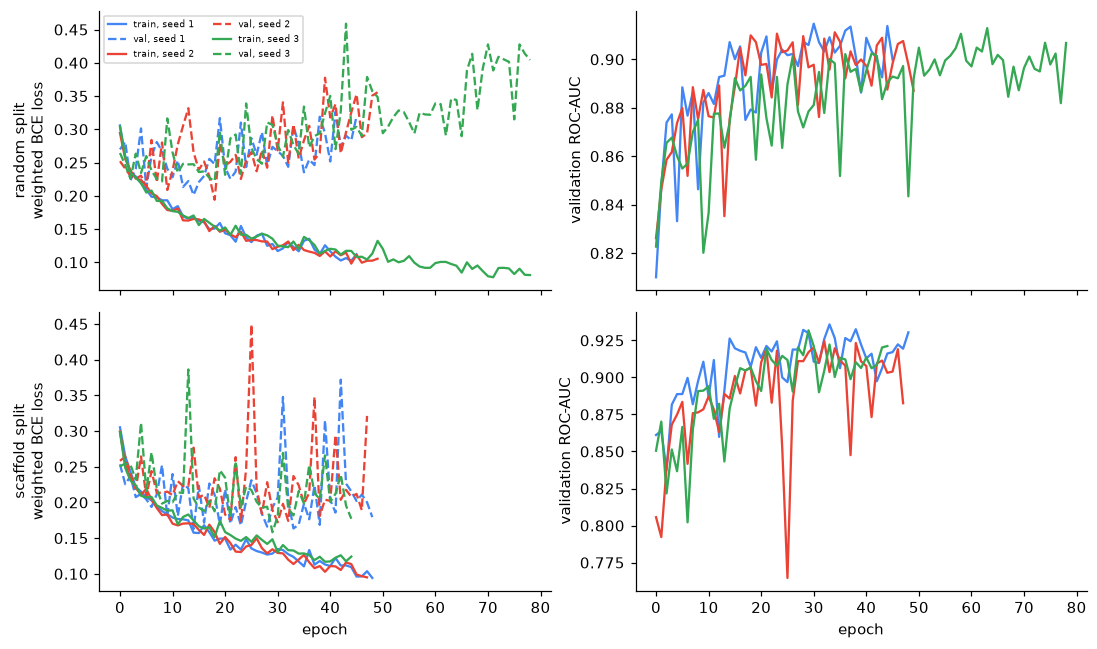

In [21]:
# Training curves for all 6 runs: loss on the left, validation ROC-AUC on the right.
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for row, split_name in enumerate(splits):
    for seed, colour in zip(MODEL_SEEDS, ["#4285F4", "#EA4335", "#34A853"]):
        history = gnn_runs[(split_name, seed)]["history"]
        axes[row, 0].plot(history["train_loss"], color=colour, label=f"train, seed {seed}")
        axes[row, 0].plot(history["val_loss"], color=colour, ls="--", label=f"val, seed {seed}")
        axes[row, 1].plot(history["val_roc_auc"], color=colour, label=f"seed {seed}")
    axes[row, 0].set_ylabel(f"{split_name} split\nweighted BCE loss"); axes[row, 1].set_ylabel("validation ROC-AUC")
axes[0, 0].legend(fontsize=6, ncol=2); axes[1, 0].set_xlabel("epoch"); axes[1, 1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("report/figures/fig_training_curves.png", dpi=170); plt.show()

Reading the curves. This is validation only, I had not seen a test number yet.

Train loss keeps dropping while validation loss turns and climbs after about epoch 20, clearest on
random seed 3. That is overfitting, and it is why the checkpoint I keep is the best-validation one,
around epoch 30 to 35 in most runs, rather than the last epoch.

Validation ROC-AUC is also jumpy and dips to 0.77 on scaffold seed 2. My guess is BatchNorm
statistics on small batches plus a validation set of only ~295 molecules, where a handful of
molecules changing rank moves the number visibly. I did not try to smooth it out. It does not affect
the checkpoint choice, and it is honest evidence that single-run differences here do not mean much,
which is why I report three seeds. No sign of underfitting, train loss gets low.

## F. Results

Both models, both splits, one table. Each threshold was picked on the matching validation set, and
each test set is being scored here for the first and only time. GNN rows are mean ± std over the 3
seeds; the per-seed rows are printed underneath so the spread is visible rather than hidden in the
std.

The three things worth reading off it: whether the GNN beats the baseline, whether the scaffold
split costs either model anything, and whether either gap is larger than the seed-to-seed noise. The
two cells after it measure that last question directly, first by comparing seed spread against the
split change, then with a paired bootstrap over the test molecules.

In [22]:
# The results table. Every test set is scored here for the first and only time.
metric_names = ["roc_auc", "pr_auc", "accuracy", "sensitivity", "specificity", "f1"]
rows = []
for split_name in splits:
    rows.append({"model": "Morgan + LogReg", "split": split_name, "n": 1, **baseline[split_name]["test"]})
    for seed in MODEL_SEEDS:
        rows.append({"model": f"GNN seed {seed}", "split": split_name, "n": 1, **gnn_runs[(split_name, seed)]["test"]})
all_runs = pd.DataFrame(rows)
all_runs.round(4).to_csv("results/all_runs_test_metrics.csv", index=False)

def format_mean_std(values) -> str:
    """Mean and sample standard deviation over the seeds, as one table cell.
    Input: the values of one metric. Output: "mean ± std" as a string."""
    return f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"

final_rows = []
for split_name in splits:
    base = baseline[split_name]["test"]
    final_rows.append({"model": "Morgan + LogReg", "split": split_name,
                       **{c: f"{base[c]:.3f}" for c in ["threshold"] + metric_names}})
    gnn_rows = all_runs[(all_runs["split"] == split_name) & all_runs["model"].str.startswith("GNN")]
    final_rows.append({"model": "GNN (3 seeds)", "split": split_name,
                       **{c: format_mean_std(gnn_rows[c]) for c in ["threshold"] + metric_names}})
comparison = pd.DataFrame(final_rows)
comparison.to_csv("results/comparison_table.csv", index=False)
display(comparison)
display(all_runs[all_runs["model"].str.startswith("GNN")].round(3).drop(columns="n"))

,model,split,threshold,roc_auc,pr_auc,accuracy,sensitivity,specificity,f1
0,Morgan + LogReg,random,0.534,0.892,0.955,0.875,0.898,0.800,0.916
1,GNN (3 seeds),random,0.406 ± 0.171,0.909 ± 0.010,0.966 ± 0.006,0.847 ± 0.021,0.868 ± 0.035,0.781 ± 0.022,0.896 ± 0.016
2,Morgan + LogReg,scaffold,0.561,0.878,0.952,0.807,0.810,0.800,0.865
3,GNN (3 seeds),scaffold,0.344 ± 0.155,0.895 ± 0.008,0.957 ± 0.008,0.833 ± 0.016,0.850 ± 0.031,0.781 ± 0.036,0.886 ± 0.013


,model,split,threshold,roc_auc,pr_auc,accuracy,sensitivity,specificity,f1
1,GNN seed 1,random,0.216,0.906,0.962,0.831,0.840,0.800,0.883
2,GNN seed 2,random,0.457,0.902,0.962,0.841,0.858,0.786,0.891
3,GNN seed 3,random,0.547,0.920,0.973,0.871,0.907,0.757,0.915
5,GNN seed 1,scaffold,0.166,0.902,0.966,0.851,0.885,0.743,0.901
6,GNN seed 2,scaffold,0.450,0.898,0.955,0.824,0.827,0.814,0.878
7,GNN seed 3,scaffold,0.416,0.886,0.950,0.824,0.836,0.786,0.879


GNN seed shown per split (best validation ROC-AUC): {'random': 1, 'scaffold': 1}


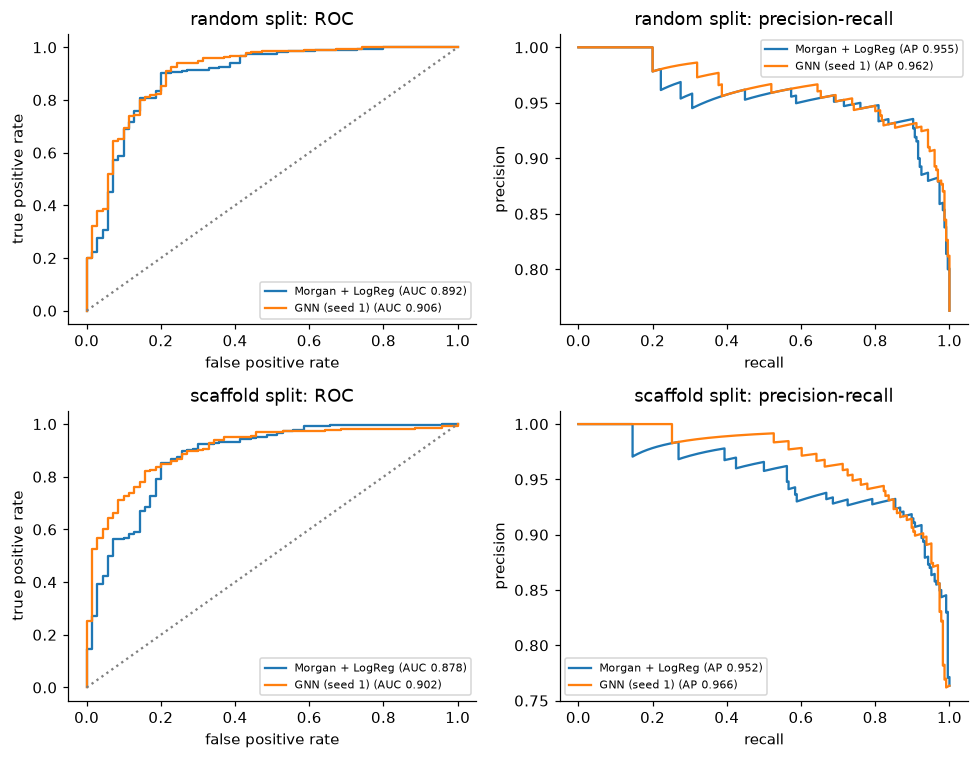

In [23]:
# figures and error analysis show one GNN run; picking it on validation keeps test out of the choice
best_seed = {}
for split_name in splits:
    val_aucs = [gnn_runs[(split_name, seed)]["val_auc"] for seed in MODEL_SEEDS]
    best_seed[split_name] = MODEL_SEEDS[int(np.argmax(val_aucs))]
print("GNN seed shown per split (best validation ROC-AUC):", best_seed)

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for row, split_name in enumerate(splits):
    y_test = y[splits[split_name]["test"]]
    curves = {"Morgan + LogReg": baseline[split_name]["p_test"],
              f"GNN (seed {best_seed[split_name]})": gnn_runs[(split_name, best_seed[split_name])]["p_test"]}
    for label, probs in curves.items():
        fpr, tpr, _ = roc_curve(y_test, probs)
        precision, recall, _ = precision_recall_curve(y_test, probs)
        axes[row, 0].plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(y_test, probs):.3f})")
        axes[row, 1].plot(recall, precision, label=f"{label} (AP {average_precision_score(y_test, probs):.3f})")
    axes[row, 0].plot([0, 1], [0, 1], color="grey", ls=":")
    axes[row, 0].set_title(f"{split_name} split: ROC"); axes[row, 1].set_title(f"{split_name} split: precision-recall")
    axes[row, 0].set_xlabel("false positive rate"); axes[row, 0].set_ylabel("true positive rate")
    axes[row, 1].set_xlabel("recall"); axes[row, 1].set_ylabel("precision")
    axes[row, 0].legend(fontsize=7); axes[row, 1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("report/figures/fig_roc_pr.png", dpi=170); plt.show()

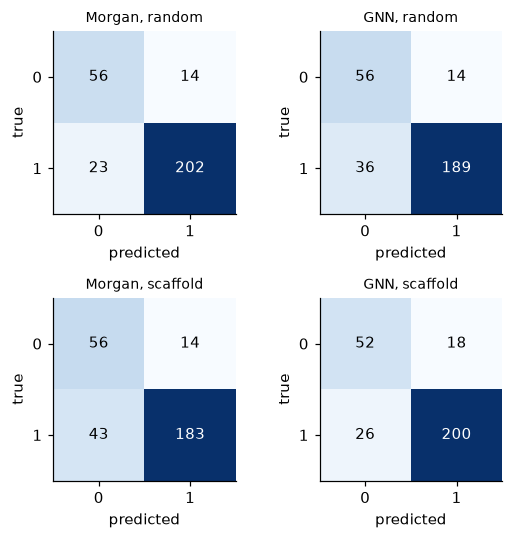

In [24]:
# Confusion matrices at each model's own frozen threshold.
fig, axes_grid = plt.subplots(2, 2, figsize=(5, 5))
axes = axes_grid.ravel()
panels = []
for split_name in splits:
    y_test = y[splits[split_name]["test"]]
    base = baseline[split_name]
    panels.append((f"Morgan, {split_name}", y_test, base["p_test"], base["threshold"]))
    run = gnn_runs[(split_name, best_seed[split_name])]
    panels.append((f"GNN, {split_name}", y_test, run["p_test"], run["threshold"]))
for ax, (title, y_test, probs, threshold) in zip(axes, panels):
    matrix = confusion_matrix(y_test, (probs >= threshold).astype(int), labels=[0, 1])
    ax.imshow(matrix, cmap="Blues")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, value, ha="center", va="center", color="white" if value > matrix.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_title(title, fontsize=9)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig("report/figures/fig_confusion.png", dpi=170); plt.show()

In [25]:
# seed variation (same split) versus the effect of changing the split
for metric in ["roc_auc", "pr_auc"]:
    by_split = {s: all_runs[(all_runs["split"] == s) & all_runs["model"].str.startswith("GNN")][metric] for s in splits}
    seed_std = np.mean([v.std(ddof=1) for v in by_split.values()])
    gap = by_split["random"].mean() - by_split["scaffold"].mean()
    print(f"GNN {metric}: mean seed std = {seed_std:.3f} | random minus scaffold mean = {gap:.3f}")
for name in ["roc_auc", "pr_auc"]:
    gap = baseline["random"]["test"][name] - baseline["scaffold"]["test"][name]
    print(f"Baseline {name}: random minus scaffold = {gap:.3f}")

GNN roc_auc: mean seed std = 0.009 | random minus scaffold mean = 0.014
GNN pr_auc: mean seed std = 0.007 | random minus scaffold mean = 0.009
Baseline roc_auc: random minus scaffold = 0.014
Baseline pr_auc: random minus scaffold = 0.003


In [26]:
# paired bootstrap over test molecules: is the GNN minus baseline ROC-AUC gap bigger than resampling noise?
rng = np.random.default_rng(SEED)
for split_name in splits:
    y_test = y[splits[split_name]["test"]]
    p_base = baseline[split_name]["p_test"]
    p_gnn = gnn_runs[(split_name, best_seed[split_name])]["p_test"]
    gaps = []
    for _ in range(1000):
        pick = rng.integers(0, len(y_test), len(y_test))
        if len(set(y_test[pick])) < 2:
            continue
        gaps.append(roc_auc_score(y_test[pick], p_gnn[pick]) - roc_auc_score(y_test[pick], p_base[pick]))
    low, high = np.percentile(gaps, [2.5, 97.5])
    print(f"{split_name}: GNN (seed {best_seed[split_name]}) minus baseline ROC-AUC = {np.mean(gaps):.3f}, 95% bootstrap interval [{low:.3f}, {high:.3f}]")

random: GNN (seed 1) minus baseline ROC-AUC = 0.014, 95% bootstrap interval [-0.025, 0.054]


scaffold: GNN (seed 1) minus baseline ROC-AUC = 0.025, 95% bootstrap interval [-0.003, 0.055]


What I take from this.

**Seeds against split.** Changing only the seed moves GNN ROC-AUC by about 0.009. Changing the split
from random to scaffold costs 0.014 for the GNN and the same 0.014 for the baseline. Those being so
close is the uncomfortable part: the penalty I expected from honest splitting is about the size of
the noise from re-running the same model. With 3 seeds and 295 test molecules I cannot separate
them, so I will not claim the scaffold split revealed a large drop. Both models do move the same
direction, and that direction agrees with section C.

**Baseline against GNN.** The GNN ranks slightly better, 0.909 vs 0.892 on random and 0.895 vs 0.878
on scaffold. But the bootstrap intervals for that gap are [-0.025, 0.054] and [-0.003, 0.055], and
both contain zero, so it is within what resampling 295 molecules produces on its own. Accuracy and
F1 do not even agree on a winner: the baseline takes random, the GNN takes scaffold. The GNN
thresholds also swing between seeds with std around 0.16, which is why I trust the AUCs more than
anything computed at a threshold.

So: comparable performance, GNN maybe slightly better at ranking, not a win. Worth saying plainly,
because it would have been easy to quote seed 3's 0.920 against 0.892 and call it a victory. On
1,965 molecules a fingerprint plus logistic regression is a hard baseline to beat.

## G. What it got wrong, and why

Scaffold test set, using the GNN seed with the best validation ROC-AUC. I show the two most confident
mistakes of each kind, each beside its most similar training molecule (Morgan Tanimoto, same
fingerprints as the baseline).

I picked the most confident ones on purpose. A borderline error at p=0.2 is just a threshold being a
threshold; a wrong answer at p=0.99 tells me something about what the model actually learned.

threshold 0.166 | false positives: 18 | false negatives: 26


,error,test_label,test_prob,similarity,train_label,train_prob
0,false positive,0,0.990,0.347,1,0.861
1,false positive,0,0.895,0.268,0,0.259
2,false negative,1,0.000,0.200,0,0.028
3,false negative,1,0.008,0.863,0,0.006


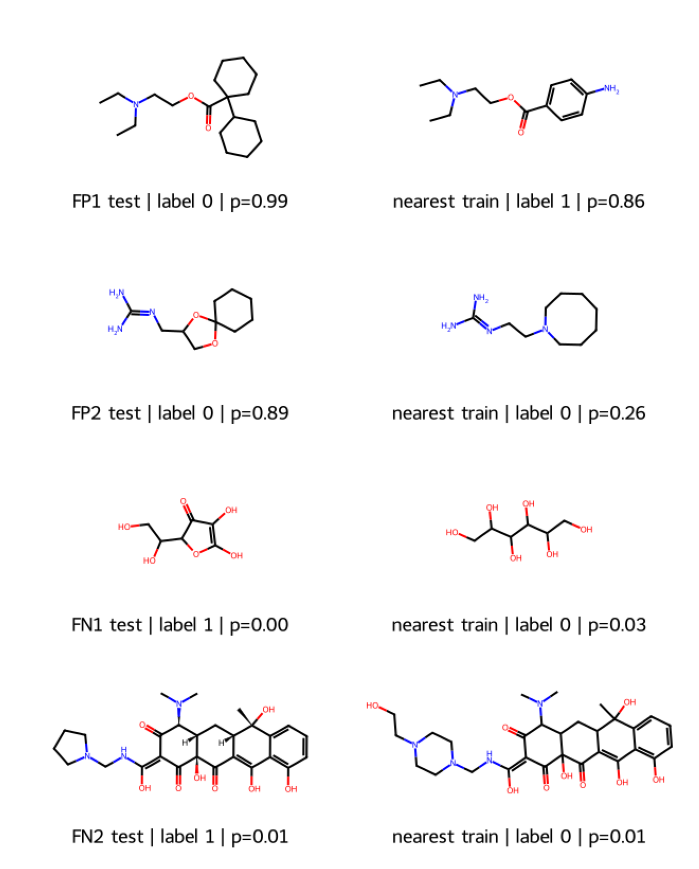

In [27]:
# The 4 most confident mistakes on the scaffold split, each beside its nearest training molecule.
split = splits["scaffold"]
run = gnn_runs[("scaffold", best_seed["scaffold"])]
threshold = run["threshold"]
y_test = y[split["test"]]
p_test = run["p_test"]

false_pos = np.where((y_test == 0) & (p_test >= threshold))[0]
false_neg = np.where((y_test == 1) & (p_test < threshold))[0]
chosen = list(false_pos[np.argsort(-p_test[false_pos])][:2]) + list(false_neg[np.argsort(p_test[false_neg])][:2])
print(f"threshold {threshold:.3f} | false positives: {len(false_pos)} | false negatives: {len(false_neg)}")

train_positions = split["train"]
train_loader = DataLoader(clean_dataset[train_positions.tolist()], batch_size=256)
p_train, _ = predict_probs(run["model"], train_loader)
train_vectors = [bit_vectors[i] for i in train_positions]

pair_rows, images, legends = [], [], []
tags = ["FP1", "FP2", "FN1", "FN2"]
for error_number, (test_index, kind) in enumerate(zip(chosen, ["false positive"] * 2 + ["false negative"] * 2)):
    position = split["test"][test_index]
    similarities = np.array(DataStructs.BulkTanimotoSimilarity(bit_vectors[position], train_vectors))
    neighbour = int(similarities.argmax())
    neighbour_position = train_positions[neighbour]
    pair_rows.append({"error": kind, "test_label": y[position], "test_prob": round(float(p_test[test_index]), 3),
                      "similarity": round(float(similarities[neighbour]), 3),
                      "train_label": y[neighbour_position], "train_prob": round(float(p_train[neighbour]), 3)})
    for pos, tag, prob in [(position, tags[error_number] + " test", p_test[test_index]), (neighbour_position, "nearest train", p_train[neighbour])]:
        images.append(Chem.MolFromSmiles(clean["smiles"].iloc[pos]))
        legends.append(f"{tag} | label {y[pos]} | p={prob:.2f}")
pair_table = pd.DataFrame(pair_rows)
pair_table.to_csv("results/error_pairs.csv", index=False)
display(pair_table)

draw_options = Draw.MolDrawOptions(); draw_options.legendFontSize = 24
grid = Draw.MolsToGridImage(images, molsPerRow=2, subImgSize=(320, 200), legends=legends,
                            drawOptions=draw_options, returnPNG=False)
plt.figure(figsize=(7, 8)); plt.imshow(grid); plt.axis("off"); plt.tight_layout()
plt.savefig("report/figures/fig_error_pairs.png", dpi=170, bbox_inches="tight"); plt.show()

Reading the errors.

**FN2** is the one similarity explains cleanly. It is a tetracycline, and its nearest training
molecule is another tetracycline at 0.86 similarity with the opposite label. The model gives both
0.01, so it copied its neighbour faithfully and the neighbour disagreed with the answer. Two almost
identical skeletons with opposite labels is either real chemistry the fingerprint cannot see, or a
labelling problem. I cannot tell which from this data.

The other three sit at 0.20 to 0.35 similarity, so the model had nothing close to go on and was
extrapolating. **FP1** is the one that bothers me: wrong at p=0.99, nearest neighbour only 0.35 away
and an amino ester resembling procaine. It looks like the model latched onto that fragment as a
penetrating-drug signal and then reported near-certainty about a molecule unlike anything it was
trained on. **FP2** is a guanidine whose nearest training molecule is also a guanidine with the same
label 0, but that neighbour gets 0.26 while the test molecule gets 0.89, so the neighbour does not
explain the error. **FN1** is ascorbic-acid-like and covered in OH groups, gets 0.00, and fits the
pattern that polar molecules do not cross. Here I would question the label before the model.

The useful lesson is that the probability carries none of this. The model is as confident about FP1,
where it had no close example, as about cases it has seen. Low similarity to training is a warning
the output does not give you.

## H. Limitations

**The labels are uncertain.** BBBP collects results from several papers that did not all measure the
same thing the same way. 10 molecules had duplicate records that disagreed with each other, which is
direct evidence of noise rather than a worry in principle, and those are only the ones that happened
to be entered twice. FN1 and FN2 above both look more like label trouble than model trouble. A
ceiling set by the labels cannot be climbed by a better model.

**There is not much data.** 1,965 molecules, 76% positive, ~295 per test set. That is why the
bootstrap interval for the model difference contains zero, and why I keep saying 0.01-0.02
differences are not interpretable. Scaffold groups also mean the val and test sets are shaped by
which families landed where, so a different seed gives a somewhat different exam, not just a
different sample.

**Nothing was checked outside the benchmark.** One dataset, two splits, no held-out lab measurement,
no prospective test, no unrelated chemical series. The scaffold split is a reasonable stand-in for
"new chemistry", but it is still these same 1,965 molecules rearranged.

**It is correlation, and only of a label.** The model learns that certain substructures accompany
certain labels. It represents no transporter, no efflux pump, no dose, no species. So it cannot
support a claim that some feature causes penetration, and a good ROC-AUC here is not evidence that
any compound is safe, effective or worth developing. Using a number from this notebook as a reason
to act on a real molecule would be a misuse of it.